In [76]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COLORS = [
    '#013162',  # A/E
    '#2a9d8f',  # VAE 1 SIGMA
    '#ffbf00',  # VAE 3 SIGMA
    '#D602B3',  # DTC ACF
    '#82bf00d4',  # DTC EUC
    '#FF6F00',  # DTC CID
]

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 14   # numbers on the axes (uncomment if needed)
plt.rcParams['ytick.labelsize'] = 14


In [77]:
# ------------------------------
# ------------ DATI ------------
# ------------------------------

MODELS = [
    'A/E',
    'VAE\n$\\pm 1 \\sigma$',
    'VAE\n$\\pm 3 \\sigma$',
    'DTC\nACF',
    'DTC\nEUC',
    'DTC\nCID',
]

# Detector V08682A
y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])

y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

# Detector V08682B
y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])

y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])


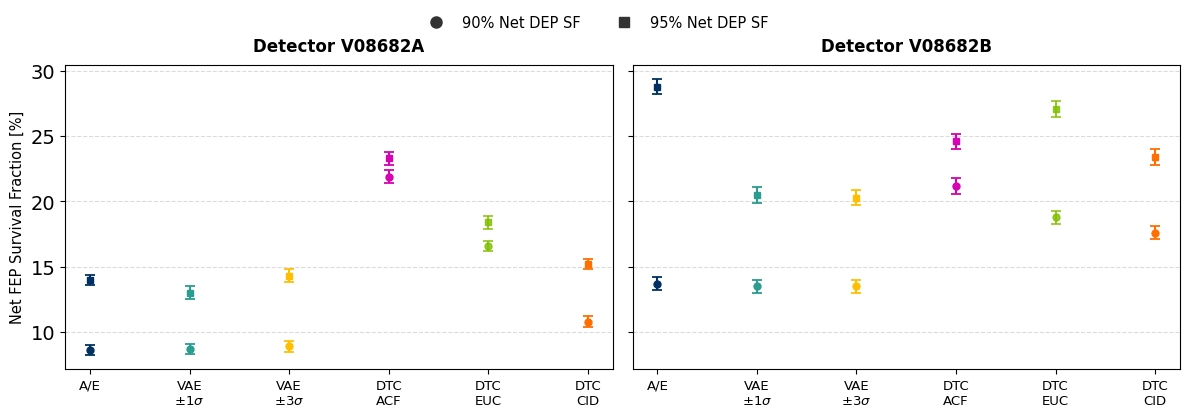

In [78]:
# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
x = np.arange(len(MODELS))
dx = 0.  # Offset orizzontale

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)


def plot_detector(ax, title, y90, err90, y95, err95, set_ylabel=False):
  for i, col in enumerate(COLORS):
    # 90% Net DEP SF -> Marker tondo ('o')
    ax.errorbar(
        x[i] - dx,
        y90[i],
        yerr=err90[i],
        fmt='o',
        color=col,
        ecolor=col,
        elinewidth=1.5,
        capsize=3.5,
        capthick=1.3,
        markersize=5,
    )

    # 95% Net DEP SF -> Marker quadrato ('s')
    ax.errorbar(
        x[i] + dx,
        y95[i],
        yerr=err95[i],
        fmt='s',
        color=col,
        ecolor=col,
        elinewidth=1.5,
        capsize=3.5,
        capthick=1.3,
        markersize=5,
    )

  ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if set_ylabel:
    ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due detector (label y attiva solo su ax1)
plot_detector(
    ax1,
    'Detector V08682A',
    y_A_90,
    err_A_90,
    y_A_95,
    err_A_95,
    set_ylabel=True,
)
plot_detector(
    ax2,
    'Detector V08682B',
    y_B_90,
    err_B_90,
    y_B_95,
    err_B_95,
    set_ylabel=False,
)

# -------------------------------------------------------------------------
# Legenda globale unica esterna (senza barre di errore)
# -------------------------------------------------------------------------
legend_handles = [
    mlines.Line2D(
        [],
        [],
        color='#333333',
        marker='o',
        linestyle='None',
        markersize=8,
        label='90% Net DEP SF',
    ),
    mlines.Line2D(
        [],
        [],
        color='#333333',
        marker='s',
        linestyle='None',
        markersize=7.5,
        label='95% Net DEP SF',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.05),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()

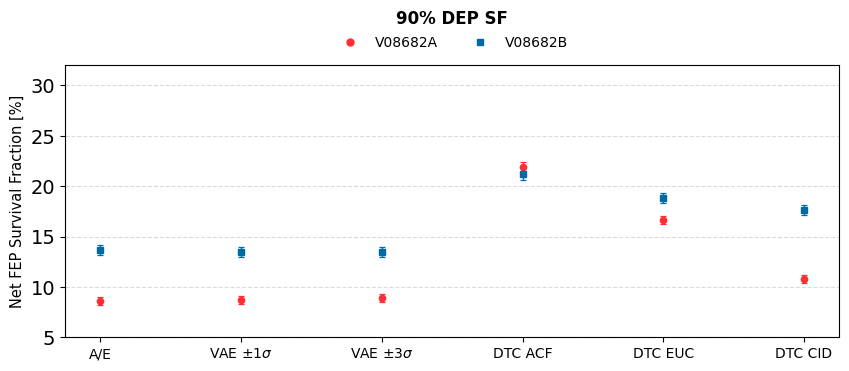

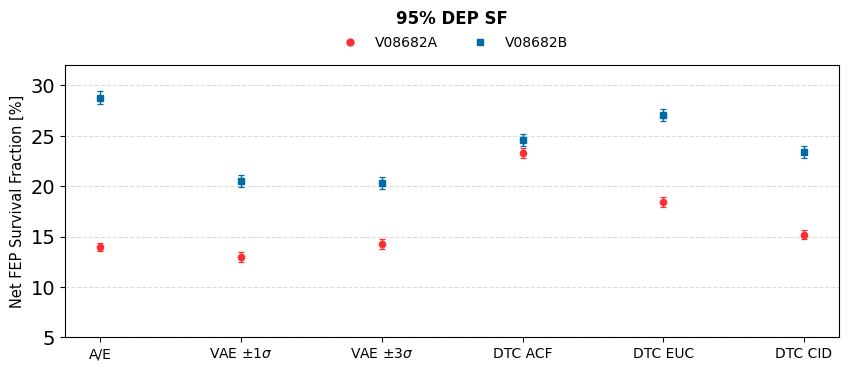

In [80]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli e valori
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0

# Range unificato calcolato sui dati (o impostato a mano, es. (5, 32))
y_min = 5.0
y_max = 32.0


def plot_cut_comparison(title, y_A, err_A, y_B, err_B):
  fig, ax = plt.subplots(figsize=(9, 4))

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      y_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      y_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
  )

  # Titolo e scala unificata
  ax.set_title(title, fontsize=12, fontweight='bold', pad=30)
  ax.set_ylim(y_min, y_max)
  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=10)
  ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')

  # Legenda esterna
  legend_handles = [
      mlines.Line2D(
          [],
          [],
          marker='o',
          markerfacecolor=COLOR_A,
          markeredgecolor=COLOR_A,
          linestyle='None',
          markersize=5,
          label='V08682A',
      ),
      mlines.Line2D(
          [],
          [],
          marker='s',
          markerfacecolor=COLOR_B,
          markeredgecolor=COLOR_B,
          linestyle='None',
          markersize=5,
          label='V08682B',
      ),
  ]

  ax.legend(
      handles=legend_handles,
      loc='lower center',
      bbox_to_anchor=(0.5, 1.01),
      ncol=2,
      frameon=False,
      fontsize=10,
  )

  # Margini fissi geometrici: blocca la dimensione esatta dell'area di plot
  plt.subplots_adjust(left=0.10, right=0.96, top=0.82, bottom=0.14)
  plt.show()


# Plot 1: Taglio 90% Net DEP SF
plot_cut_comparison('90% DEP SF', y_A_90, err_A_90, y_B_90, err_B_90)

# Plot 2: Taglio 95% Net DEP SF
plot_cut_comparison('95% DEP SF', y_A_95, err_A_95, y_B_95, err_B_95)

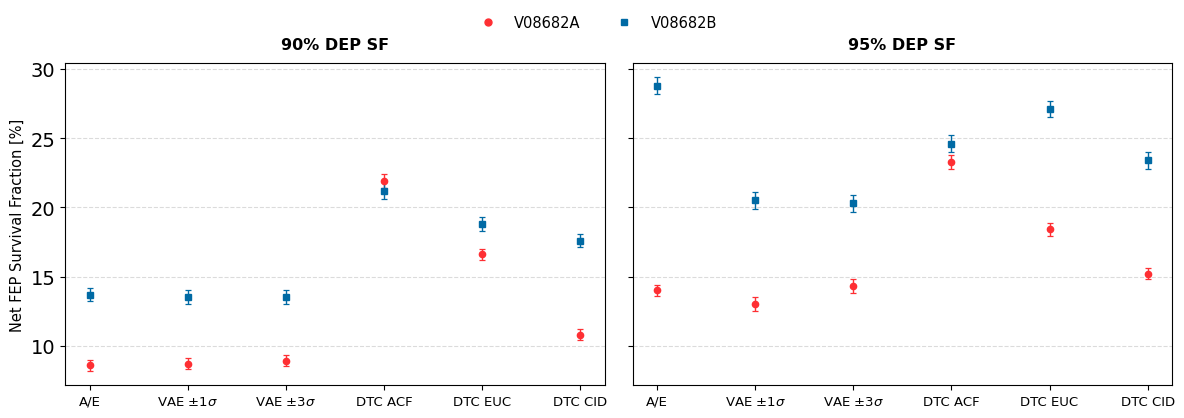

In [81]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli e valori
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0

# Due subplot affiancati con sharey=True
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)


def plot_subplot(ax, title_text, y_A, err_A, y_B, err_B, is_left=False):
  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      y_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      y_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
  )

  # Titolo inserito all'interno del plot (in alto al centro)
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if is_left:
    ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due tagli
plot_subplot(
    ax1, '90% DEP SF', y_A_90, err_A_90, y_B_90, err_B_90, is_left=True
)
plot_subplot(
    ax2, '95% DEP SF', y_A_95, err_A_95, y_B_95, err_B_95, is_left=False
)

# Legenda unica esterna posizionata appena sopra i due frame
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()

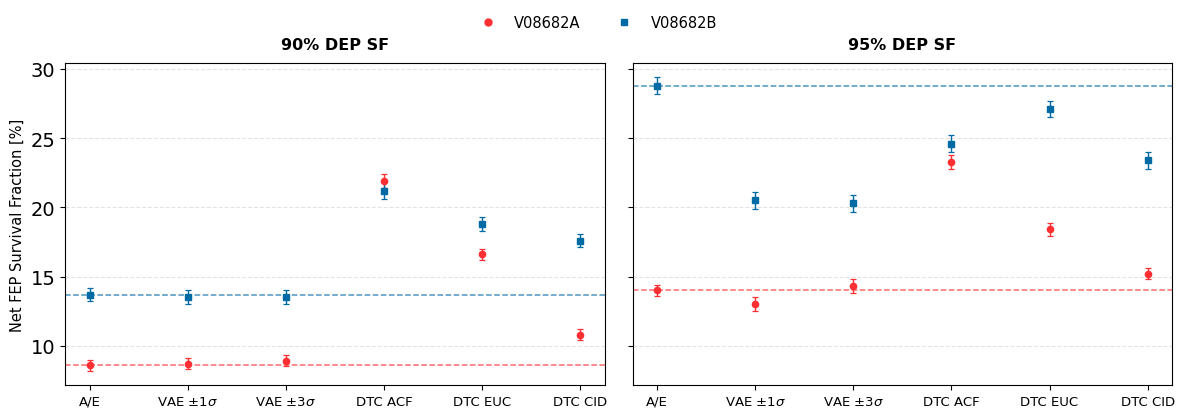

In [82]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli e valori
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0

# Due subplot affiancati con sharey=True
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)


def plot_subplot(ax, title_text, y_A, err_A, y_B, err_B, is_left=False):
  # Linee orizzontali tratteggiate di riferimento al valore A/E (indice 0)
  ax.axhline(
      y=y_A[0],
      color=COLOR_A,
      linestyle='--',
      linewidth=1.1,
      alpha=0.7,
      zorder=1,
  )
  ax.axhline(
      y=y_B[0],
      color=COLOR_B,
      linestyle='--',
      linewidth=1.1,
      alpha=0.7,
      zorder=1,
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      y_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      y_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if is_left:
    ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.35, axis='y')


# Disegna i due tagli
plot_subplot(
    ax1, '90% DEP SF', y_A_90, err_A_90, y_B_90, err_B_90, is_left=True
)
plot_subplot(
    ax2, '95% DEP SF', y_A_95, err_A_95, y_B_95, err_B_95, is_left=False
)

# Legenda unica esterna
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()

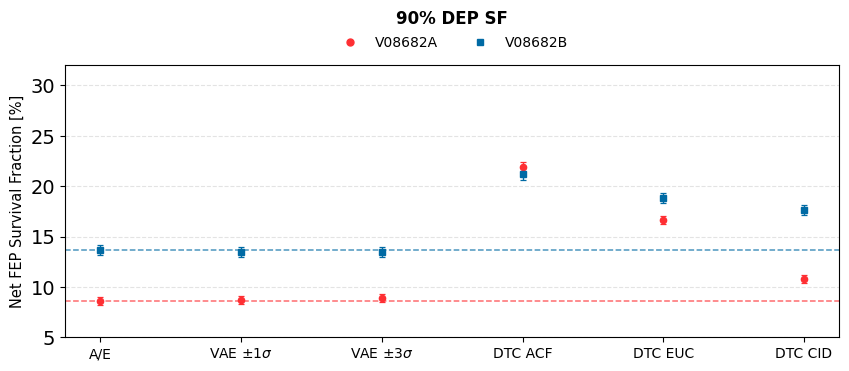

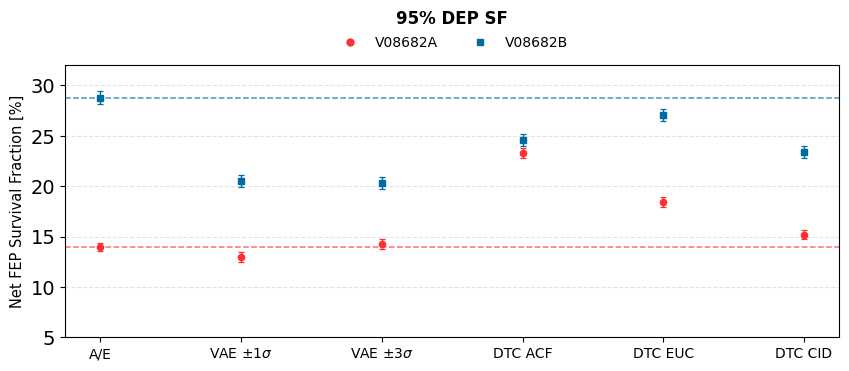

In [83]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli e valori
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0

# Range unificato
y_min = 5.0
y_max = 32.0


def plot_cut_comparison(title, y_A, err_A, y_B, err_B):
  fig, ax = plt.subplots(figsize=(9, 4))

  # Linee orizzontali tratteggiate di riferimento al valore A/E (indice 0)
  ax.axhline(
      y=y_A[0],
      color=COLOR_A,
      linestyle='--',
      linewidth=1.1,
      alpha=0.7,
      zorder=1,
  )
  ax.axhline(
      y=y_B[0],
      color=COLOR_B,
      linestyle='--',
      linewidth=1.1,
      alpha=0.7,
      zorder=1,
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      y_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      y_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo e scala unificata
  ax.set_title(title, fontsize=12, fontweight='bold', pad=30)
  ax.set_ylim(y_min, y_max)
  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=10)
  ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.35, axis='y')

  # Legenda esterna
  legend_handles = [
      mlines.Line2D(
          [],
          [],
          marker='o',
          markerfacecolor=COLOR_A,
          markeredgecolor=COLOR_A,
          linestyle='None',
          markersize=5,
          label='V08682A',
      ),
      mlines.Line2D(
          [],
          [],
          marker='s',
          markerfacecolor=COLOR_B,
          markeredgecolor=COLOR_B,
          linestyle='None',
          markersize=5,
          label='V08682B',
      ),
  ]

  ax.legend(
      handles=legend_handles,
      loc='lower center',
      bbox_to_anchor=(0.5, 1.01),
      ncol=2,
      frameon=False,
      fontsize=10,
  )

  # Margini fissi geometrici: blocca la dimensione esatta dell'area di plot
  plt.subplots_adjust(left=0.10, right=0.96, top=0.82, bottom=0.14)
  plt.show()


# Plot 1: Taglio 90% Net DEP SF
plot_cut_comparison('90% DEP SF', y_A_90, err_A_90, y_B_90, err_B_90)

# Plot 2: Taglio 95% Net DEP SF
plot_cut_comparison('95% DEP SF', y_A_95, err_A_95, y_B_95, err_B_95)

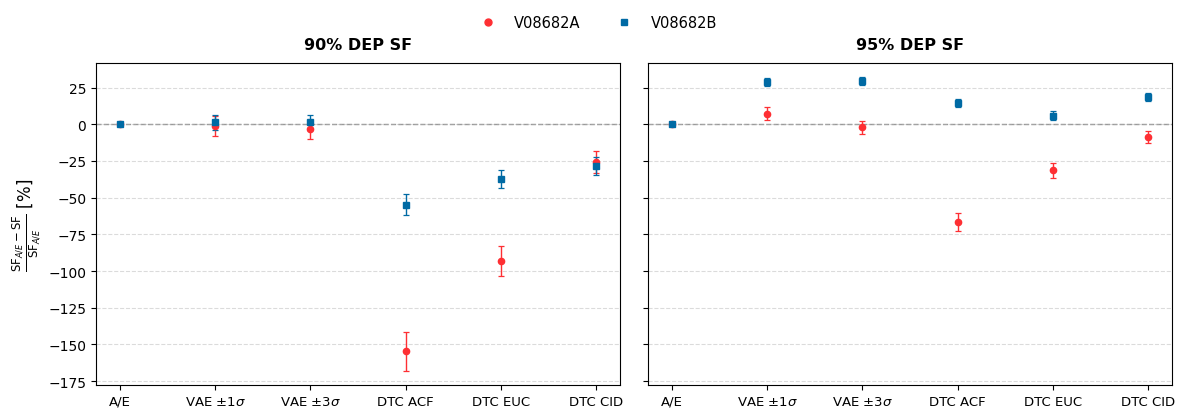

In [ ]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli e valori
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0


# -------------------------------------------------------------------------
# Calcolo variazione percentuale e propagazione incertezze
# Δ = (SF_AE - SF_alg) / SF_AE * 100 = (1 - SF_alg / SF_AE) * 100
# -------------------------------------------------------------------------
def compute_relative_diff(y, err):
  y_ae = y[0]
  err_ae = err[0]

  # Variazione percentuale [%]
  delta = ((y_ae - y) / y_ae) * 100.0

  # Propagazione errore sul rapporto R = y / y_ae
  rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
  delta_err = 100.0 * (y / y_ae) * np.sqrt(rel_err_sq)
  delta_err[0] = 0.0  # Per A/E la variazione rispetto a se stesso è identicamente 0

  return delta, delta_err


delta_A_90, err_delta_A_90 = compute_relative_diff(y_A_90, err_A_90)
delta_A_95, err_delta_A_95 = compute_relative_diff(y_A_95, err_A_95)

delta_B_90, err_delta_B_90 = compute_relative_diff(y_B_90, err_B_90)
delta_B_95, err_delta_B_95 = compute_relative_diff(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)


def plot_subplot(
    ax, title_text, delta_A, err_A, delta_B, err_B, is_left=False
):
  # Linea di riferimento a 0% (valore A/E)
  ax.axhline(
      y=0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      delta_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      delta_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo interno al plot
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if is_left:
    ax.set_ylabel(
        r'$\frac{\mathrm{SF}_{A/E} - \mathrm{SF}}{\mathrm{SF}_{A/E}} \ [\%]$',
        fontsize=12,
    )
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due subplot
plot_subplot(
    ax1,
    '90% DEP SF',
    delta_A_90,
    err_delta_A_90,
    delta_B_90,
    err_delta_B_90,
    is_left=True,
)
plot_subplot(
    ax2,
    '95% DEP SF',
    delta_A_95,
    err_delta_A_95,
    delta_B_95,
    err_delta_B_95,
    is_left=False,
)

# Legenda esterna superiore
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()

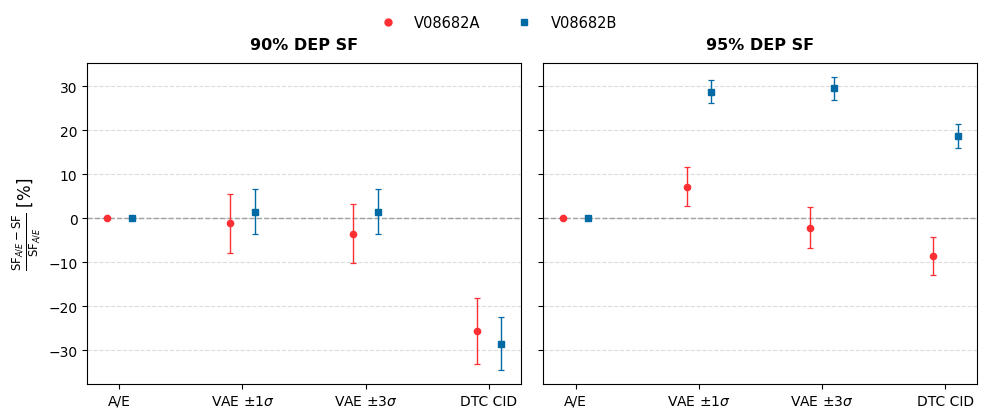

In [ ]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli selezionati (esclusi ACF ed EUC)
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC CID',
]

# Indici corrispondenti ai modelli selezionati rispetto alla lista originale:
# 0: A/E, 1: VAE ±1σ, 2: VAE ±3σ, 5: DTC CID
idx_keep = [0, 1, 2, 5]

# Dati originali
y_A_90_full = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90_full = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95_full = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95_full = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90_full = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90_full = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95_full = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95_full = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Selezione dei soli modelli desiderati
y_A_90 = y_A_90_full[idx_keep]
err_A_90 = err_A_90_full[idx_keep]
y_A_95 = y_A_95_full[idx_keep]
err_A_95 = err_A_95_full[idx_keep]

y_B_90 = y_B_90_full[idx_keep]
err_B_90 = err_B_90_full[idx_keep]
y_B_95 = y_B_95_full[idx_keep]
err_B_95 = err_B_95_full[idx_keep]

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.1

# -------------------------------------------------------------------------
# Calcolo variazione percentuale e propagazione incertezze
# Δ = (SF_AE - SF_alg) / SF_AE * 100
# -------------------------------------------------------------------------
def compute_relative_diff(y, err):
  y_ae = y[0]
  err_ae = err[0]

  # Variazione percentuale [%]
  delta = ((y_ae - y) / y_ae) * 100.0

  # Propagazione dell'errore
  rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
  delta_err = 100.0 * (y / y_ae) * np.sqrt(rel_err_sq)
  delta_err[0] = 0.0

  return delta, delta_err


delta_A_90, err_delta_A_90 = compute_relative_diff(y_A_90, err_A_90)
delta_A_95, err_delta_A_95 = compute_relative_diff(y_A_95, err_A_95)

delta_B_90, err_delta_B_90 = compute_relative_diff(y_B_90, err_B_90)
delta_B_95, err_delta_B_95 = compute_relative_diff(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)


def plot_subplot(
    ax, title_text, delta_A, err_A, delta_B, err_B, is_left=False
):
  # Linea di riferimento a 0% (valore A/E)
  ax.axhline(
      y=0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      delta_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      delta_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo interno al plot
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=10)
  if is_left:
    ax.set_ylabel(
        r'$\frac{\mathrm{SF}_{A/E} - \mathrm{SF}}{\mathrm{SF}_{A/E}} \ [\%]$',
        fontsize=12,
    )
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due subplot
plot_subplot(
    ax1,
    '90% DEP SF',
    delta_A_90,
    err_delta_A_90,
    delta_B_90,
    err_delta_B_90,
    is_left=True,
)
plot_subplot(
    ax2,
    '95% DEP SF',
    delta_A_95,
    err_delta_A_95,
    delta_B_95,
    err_delta_B_95,
    is_left=False,
)

# Legenda esterna superiore
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()

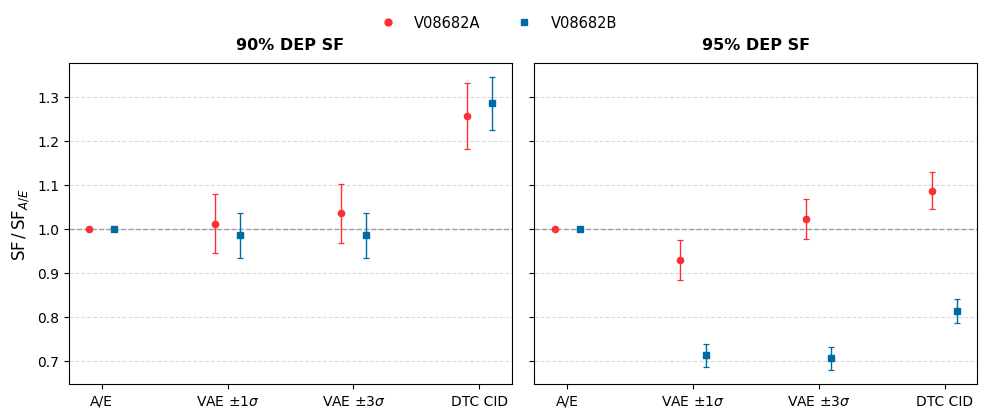

In [8]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli selezionati (esclusi ACF ed EUC)
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC CID',
]

# Indici corrispondenti ai modelli selezionati:
# 0: A/E, 1: VAE ±1σ, 2: VAE ±3σ, 5: DTC CID
idx_keep = [0, 1, 2, 5]

# Dati originali
y_A_90_full = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90_full = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95_full = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95_full = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90_full = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90_full = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95_full = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95_full = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Selezione modelli
y_A_90 = y_A_90_full[idx_keep]
err_A_90 = err_A_90_full[idx_keep]
y_A_95 = y_A_95_full[idx_keep]
err_A_95 = err_A_95_full[idx_keep]

y_B_90 = y_B_90_full[idx_keep]
err_B_90 = err_B_90_full[idx_keep]
y_B_95 = y_B_95_full[idx_keep]
err_B_95 = err_B_95_full[idx_keep]

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.1


# -------------------------------------------------------------------------
# Calcolo rapporto R = SF_algoritmo / SF_AE e propagazione incertezze
# -------------------------------------------------------------------------
def compute_ratio(y, err):
  y_ae = y[0]
  err_ae = err[0]

  # Rapporto
  ratio = y / y_ae

  # Propagazione errore sul rapporto
  rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
  ratio_err = ratio * np.sqrt(rel_err_sq)
  ratio_err[0] = 0.0  # Per A/E il rapporto con se stesso è identicamente 1

  return ratio, ratio_err


ratio_A_90, err_ratio_A_90 = compute_ratio(y_A_90, err_A_90)
ratio_A_95, err_ratio_A_95 = compute_ratio(y_A_95, err_A_95)

ratio_B_90, err_ratio_B_90 = compute_ratio(y_B_90, err_B_90)
ratio_B_95, err_ratio_B_95 = compute_ratio(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)


def plot_subplot(
    ax, title_text, ratio_A, err_A, ratio_B, err_B, is_left=False
):
  # Linea di riferimento a 1.0 (valore di A/E)
  ax.axhline(
      y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      ratio_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      ratio_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo interno al plot
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=10)
  if is_left:
    ax.set_ylabel(r'$\mathrm{SF} \,/\, \mathrm{SF}_{A/E}$', fontsize=12)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due subplot
plot_subplot(
    ax1,
    '90% DEP SF',
    ratio_A_90,
    err_ratio_A_90,
    ratio_B_90,
    err_ratio_B_90,
    is_left=True,
)
plot_subplot(
    ax2,
    '95% DEP SF',
    ratio_A_95,
    err_ratio_A_95,
    ratio_B_95,
    err_ratio_B_95,
    is_left=False,
)

# Legenda esterna superiore
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()

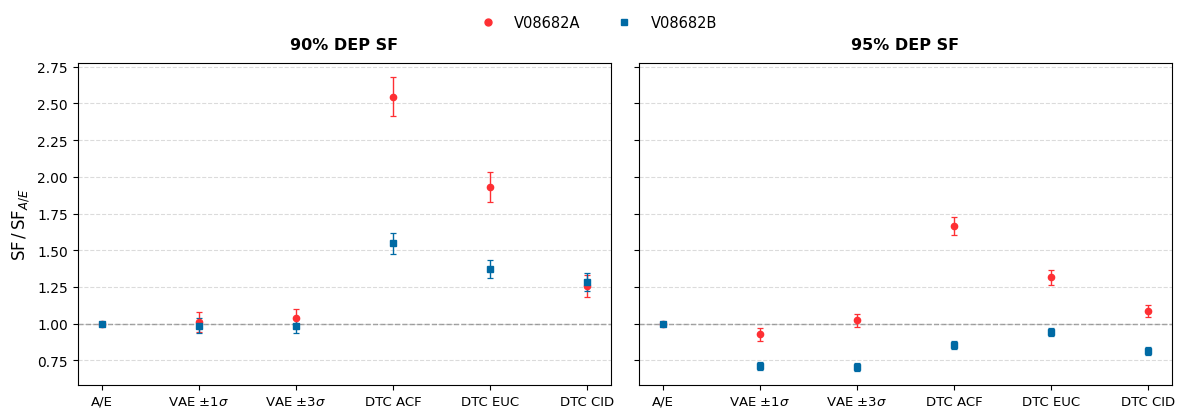

In [6]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Tutti i modelli
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

# Dati completi
y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0


# -------------------------------------------------------------------------
# Calcolo rapporto R = SF_algoritmo / SF_AE e propagazione incertezze
# -------------------------------------------------------------------------
def compute_ratio(y, err):
  y_ae = y[0]
  err_ae = err[0]

  # Rapporto
  ratio = y / y_ae

  # Propagazione errore sul rapporto: σ_R = R * sqrt((σ/y)^2 + (σ_ae/y_ae)^2)
  rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
  ratio_err = ratio * np.sqrt(rel_err_sq)
  ratio_err[0] = 0.0  # Per A/E il rapporto con se stesso è identicamente 1

  return ratio, ratio_err


ratio_A_90, err_ratio_A_90 = compute_ratio(y_A_90, err_A_90)
ratio_A_95, err_ratio_A_95 = compute_ratio(y_A_95, err_A_95)

ratio_B_90, err_ratio_B_90 = compute_ratio(y_B_90, err_B_90)
ratio_B_95, err_ratio_B_95 = compute_ratio(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)


def plot_subplot(
    ax, title_text, ratio_A, err_A, ratio_B, err_B, is_left=False
):
  # Linea di riferimento a 1.0 (valore di A/E)
  ax.axhline(
      y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      ratio_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      ratio_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo interno al plot (in alto al centro)
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if is_left:
    ax.set_ylabel(r'$\mathrm{SF} \,/\, \mathrm{SF}_{A/E}$', fontsize=12)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due subplot
plot_subplot(
    ax1,
    '90% DEP SF',
    ratio_A_90,
    err_ratio_A_90,
    ratio_B_90,
    err_ratio_B_90,
    is_left=True,
)
plot_subplot(
    ax2,
    '95% DEP SF',
    ratio_A_95,
    err_ratio_A_95,
    ratio_B_95,
    err_ratio_B_95,
    is_left=False,
)

# Legenda esterna superiore
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.show()